<a href="https://colab.research.google.com/github/rimfa/vision-transformer-from-scratch/blob/main/ViT_from_scratch.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Vision Transformer (ViT) from Scratch

## 1. Introduction

### Что такое Vision Transformer?

**Vision Transformer (ViT)** — это архитектура нейронной сети, которая применяет механизм Transformer к задачам компьютерного зрения.

В классических сверточных нейронных сетях (CNN) изображение обрабатывается с помощью **kernels (фильтров свертки)**, которые извлекают локальные признаки: границы, текстуры, формы и т. д.

В ViT подход немного другой. Вместо того чтобы последовательно извлекать признаки с помощью сверточных фильтров, мы разбиваем изображение на небольшие участки — **patches (патчи)** — и преобразуем каждый из них в векторное представление.

По сути, мы представляем изображение в виде последовательности токенов, как это делается с текстом в NLP. Разница в том, что здесь каждый токен соответствует не слову, а определённому участку изображения.

Далее эти токены обрабатываются с помощью **Self-Attention**, который позволяет каждому патчу учитывать информацию из других патчей изображения, независимо от того, насколько далеко они расположены друг от друга.

Таким образом, ViT не задаёт заранее локальные связи между токенами так, как это делают сверточные фильтры. Модель сама учится определять, какие области изображения важны друг для друга.

### Принцип работы ViT

![Vision Transformer Architecture](images/vit_figure.png)

**1. Patch Embedding**

Сначала изображение разбивается на непересекающиеся патчи фиксированного размера.

Каждый патч разворачивается в одномерный вектор (Flatten), после чего проходит через обучаемую линейную проекцию (Linear Projection).

В результате мы получаем последовательность эмбеддингов. Количество токенов при этом не меняется, но размерность их векторных представлений становится равной выбранной размерности эмбеддинга.

**2. CLS Token**

К полученной последовательности добавляется отдельный обучаемый токен — **CLS (Classification Token)**.

Изначально его вектор инициализируется случайными значениями и не содержит информации о самом изображении. В отличие от остальных токенов, он не соответствует какому-то конкретному патчу.

Зачем он нужен? Через Self-Attention CLS-токен может взаимодействовать со всеми остальными токенами и постепенно учится формировать общее представление изображения, которое затем используется для классификации.

**3. Positional Embedding**

Проблема Self-Attention заключается в том, что сам по себе этот механизм не знает, где именно находился каждый патч на исходном изображении.

Поэтому мы добавляем к эмбеддингам токенов обучаемые **позиционные эмбеддинги (Positional Embeddings)**, которые позволяют модели учитывать их расположение.

При этом позиционные эмбеддинги именно складываются с представлениями токенов, а не конкатенируются с ними, поэтому размерность векторов остаётся прежней.

**4. Transformer Encoder**

Далее вся последовательность токенов, включая CLS, проходит через несколько Transformer Encoder Blocks.

Основной механизм здесь — **Multi-Head Self-Attention**.

Для каждого токена вычисляются три представления: Query (Q), Key (K) и Value (V). С помощью Q и K определяются веса внимания между токенами, после чего на основе этих весов и V формируются новые векторные представления.

То есть каждый токен получает обновлённое представление, в котором уже учитывается информация от других токенов изображения.

Использование нескольких голов внимания (Multi-Head Attention) позволяет параллельно обучать разные способы взаимодействия между токенами.

Помимо Self-Attention, каждый блок включает **LayerNorm, MLP и Residual Connections**, которые участвуют в преобразовании представлений и помогают обучению модели.

**5. Classification Head**

После прохождения всех Transformer Encoder Blocks мы получаем обновлённые представления всех токенов.

Для классификации используется итоговое представление **CLS-токена**, которое передаётся в классификационную голову (Classification Head).

На выходе модель получает значения для каждого класса изображения — logits, по которым определяется предсказанный класс.

## 2. Dataset Preparation

Для обучения и экспериментов используется **Fashion-MNIST** — датасет из 10 классов изображений одежды и обуви.

Данные разделяются на три выборки:
- **Train:** 10 000 изображений (по 1000 на класс).
- **Validation:** 2 000 изображений (по 200 на класс).
- **Test:** 10 000 изображений.

Изображения нормализуются из диапазона `[0, 255]` в `[-1, 1]`.

**Размерности данных:**

- Одно изображение: `(1, 28, 28)` — каналы, высота, ширина.
- Батч изображений: `(B, 1, 28, 28)`.
- Метки классов: `(B,)`.

Здесь `B` — размер батча. При дальнейшем разбиении изображения на патчи размерности тензоров будут изменяться.

In [1]:
import random
import numpy as np
import torch
from torch import nn
from torch.nn import functional as F

from pathlib import Path
from torch.utils.data import DataLoader, TensorDataset
from torchvision.datasets import FashionMNIST

SEED = 100
BATCH_SIZE = 128

torch.manual_seed(SEED)

train_data = FashionMNIST("data", train=True, download=True)
test_data = FashionMNIST("data", train=False, download=True)

# Train / Validation split
train_idx, val_idx = [], []
g = torch.Generator().manual_seed(SEED)

for label in range(10):
    idx = torch.where(train_data.targets == label)[0]
    idx = idx[torch.randperm(len(idx), generator=g)]

    train_idx.extend(idx[:1000].tolist())
    val_idx.extend(idx[1000:1200].tolist())

# Normalization
def prepare_data(dataset, indices):
    x = dataset.data[indices].float().unsqueeze(1) / 127.5 - 1
    y = dataset.targets[indices]
    return TensorDataset(x, y)

train_set = prepare_data(train_data, train_idx)
val_set = prepare_data(train_data, val_idx)
test_set = prepare_data(test_data, torch.arange(len(test_data)))

# DataLoaders
def make_loaders(batch_size=BATCH_SIZE):
    train_loader = DataLoader(train_set, batch_size=batch_size, shuffle=True, generator=torch.Generator().manual_seed(SEED))

    val_loader = DataLoader(val_set,batch_size=batch_size,shuffle=False)
    test_loader = DataLoader(test_set,batch_size=batch_size,shuffle=False)
    return train_loader, val_loader, test_loader

train_loader, val_loader, test_loader = make_loaders()
print(f"Train: {len(train_set)}")
print(f"Validation: {len(val_set)}")
print(f"Test: {len(test_set)}")

100%|██████████| 26.4M/26.4M [00:02<00:00, 12.7MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 202kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.77MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 26.0MB/s]


Train: 10000
Validation: 2000
Test: 10000


In [2]:
import time
device = torch.device("cuda" if torch.cuda.is_available() else
                      "mps" if torch.backends.mps.is_available() else "cpu")
# Используем эту функцию при измерении времени обучения.
def synchronize():
    # Операции GPU асинхронны; перед измерением времени нужна синхронизация.
    if device.type == "cuda":
        torch.cuda.synchronize()
    elif device.type == "mps":
        torch.mps.synchronize()
device

device(type='cuda')


### Data Shapes

Каждое изображение Fashion-MNIST — одноканальная матрица размером $28 \times 28$:

$$
X =
\begin{bmatrix}
x_{1,1} & \cdots & x_{1,28} \\
\vdots & \ddots & \vdots \\
x_{28,1} & \cdots & x_{28,28}
\end{bmatrix}
\in \mathbb{R}^{28 \times 28}
$$

После добавления размерности канала:

$$
X \in \mathbb{R}^{1 \times 28 \times 28}
$$

**Размерности выборок:**

$$
\begin{aligned}
X_{\text{train}} &\in \mathbb{R}^{10000 \times 1 \times 28 \times 28} \\
X_{\text{val}} &\in \mathbb{R}^{2000 \times 1 \times 28 \times 28} \\
X_{\text{test}} &\in \mathbb{R}^{10000 \times 1 \times 28 \times 28}
\end{aligned}
$$

**Размерности одного батча:**

$$
\boxed{
\begin{aligned}
X_{\text{batch}} &\in \mathbb{R}^{B \times 1 \times 28 \times 28} \\
y_{\text{batch}} &\in \{0,\ldots,9\}^{B}
\end{aligned}
}
$$

где $B = 128$ — размер батча (кроме последнего неполного батча), а $y$ — метки классов.

Значения пикселей нормализованы в диапазон $[-1, 1]$.


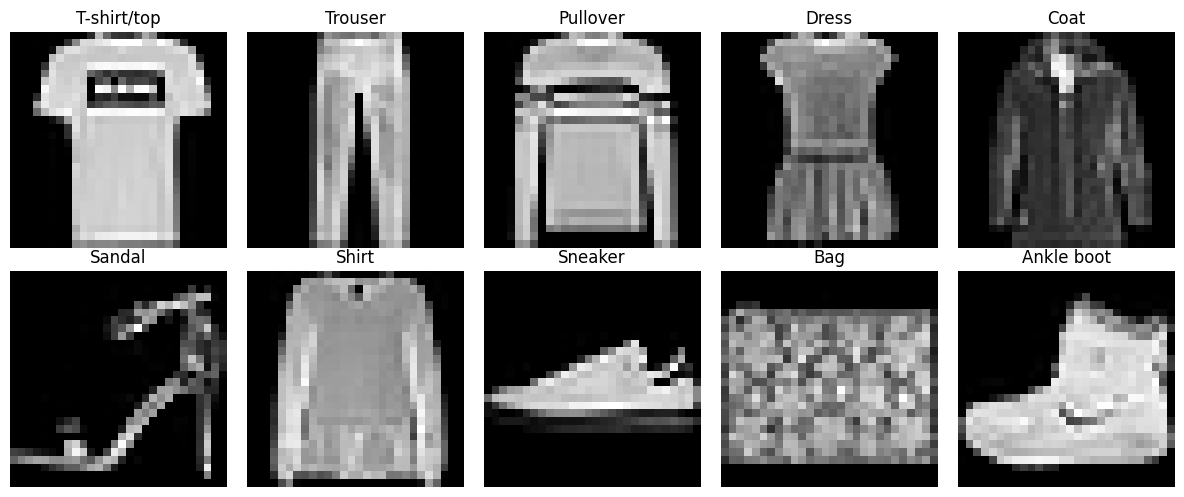

In [3]:
import matplotlib.pyplot as plt

class_names = train_data.classes

fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for label, ax in enumerate(axes.flat):
    idx = (train_data.targets == label).nonzero()[0].item()

    ax.imshow(train_data.data[idx], cmap="gray")
    ax.set_title(class_names[label])
    ax.axis("off")

plt.tight_layout()
plt.show()

## 3. Patch Embedding

![Patch Embedding](images/patch_emb.png)
На первом этапе изображение разбивается на непересекающиеся патчи фиксированного размера $P \times P$.

Каждый патч содержит часть исходного изображения и преобразуется в векторное представление (embedding) размерности $D$.

Количество патчей определяется как:

$$
N = \frac{H \cdot W}{P^2}
$$

где:
- $H, W$ — высота и ширина изображения;
- $P$ — размер стороны патча;
- $N$ — количество патчей;
- $D$ — размерность эмбеддинга.

Для Fashion-MNIST при размере изображения $28 \times 28$ и размере патча $4 \times 4$:

$$
N = \frac{28 \cdot 28}{4^2} = 49
$$

Таким образом, каждое изображение будет представлено последовательностью из **49 токенов**.

### Реализация через Conv2d

Вместо явного разбиения изображения на патчи, их разворачивания (Flatten) и последующей линейной проекции можно использовать **Conv2d**.

Если задать `kernel_size = patch_size`(что бы области не)и `stride = patch_size`, каждый фильтр будет обрабатывать отдельный непересекающийся патч.

При этом каждый из $D$ фильтров вычисляет одну координату будущего эмбеддинга.

**Изменение размерностей:**

$$
\underbrace{(B, C, H, W)}_{\text{Input}}
\xrightarrow{\text{Conv2d}}
\underbrace{\left(B, D, \frac{H}{P}, \frac{W}{P}\right)}_{\text{Projection}}
\xrightarrow{\text{Flatten + Transpose}}
\underbrace{(B, N, D)}_{\text{Patch Embeddings}}
$$

Для нашего случая при $D=128$:

$$
(B, 1, 28, 28)
\rightarrow
(B, 128, 7, 7)
\rightarrow
\boxed{(B, 49, 128)}
$$

На выходе мы получаем последовательность из 49 токенов, каждый из которых представлен обучаемым эмбеддингом размерности 128.

In [4]:
class PatchEmbedding(nn.Module):
  def __init__(self, image_size, patch_size, in_channels, embedding_dim):
    super().__init__()

    if image_size % patch_size != 0:
      raise AssertionError("Image size must be divisible by patch size")

    self.patch_size = patch_size
    self.image_size = image_size
    self.embedding_dim = embedding_dim

    self.patch_projection = nn.Conv2d(
        in_channels=in_channels,
        out_channels=self.embedding_dim,
        kernel_size=self.patch_size,
        stride=self.patch_size
    )
  def forward(self, images):
      if images.ndim != 4:
          raise ValueError("Expected 4D input (B, C, H, W)")

      if images.shape[1:] != (1, self.image_size, self.image_size):
          raise ValueError("Incorrect image dimensions")

      patches = self.patch_projection(images).flatten(2)
      patches = patches.permute(0, 2, 1)

      return patches


In [5]:
patch_embedding = PatchEmbedding(
    image_size=28,
    patch_size=4,
    in_channels=1,
    embedding_dim=128
)

images, labels = next(iter(train_loader))
patches = patch_embedding(images)

print("Input shape:", images.shape)
print("Output shape:", patches.shape)
print("Number of patches:", patches.shape[1])
print("Embedding dimension:", patches.shape[2])

Input shape: torch.Size([128, 1, 28, 28])
Output shape: torch.Size([128, 49, 128])
Number of patches: 49
Embedding dimension: 128


In [6]:
patch_test = PatchEmbedding(8, 4, 1, 3)
assert isinstance(patch_test.patch_projection, nn.Conv2d), 'Используйте Conv2d для выделения патчей и их проекции.'
with torch.no_grad():
    patch_test.patch_projection.weight.zero_()
    patch_test.patch_projection.bias.zero_()
    patch_test.patch_projection.weight[0, 0] = 1.0       # Сумма всех 16 пикселей.
    patch_test.patch_projection.weight[1, 0, 0, 0] = 1.0  # Верхний левый пиксель.
    patch_test.patch_projection.weight[2, 0, -1, -1] = 1.0 # Нижний правый пиксель.
    actual = patch_test(torch.arange(64.).reshape(1, 1, 8, 8))
expected = torch.tensor([[[216., 0., 27.], [280., 4., 31.],
                          [728., 32., 59.], [792., 36., 63.]]])
torch.testing.assert_close(actual, expected)
assert PatchEmbedding(28, 7, 1, 16)(torch.randn(2, 1, 28, 28)).shape == (2, 16, 16)
print('✓ Порядок и форма выходных токенов корректны.')

✓ Порядок и форма выходных токенов корректны.


### Result

Реализация Patch Embedding работает корректно. Изображения преобразуются в последовательность патчей, каждый из которых представлен эмбеддингом заданной размерности.


## 4. Multi-Head Self-Attention

После Patch Embedding каждый патч представлен отдельным эмбеддингом. Следующий этап — обработка полученной последовательности с помощью механизма **Multi-Head Self-Attention**.

Основная идея Self-Attention заключается в том, что каждый токен может учитывать информацию от остальных токенов последовательности. Таким образом, представление каждого патча обогащается контекстной информацией из других областей изображения.

### Принцип работы

1. **Q, K, V.** Для каждого эмбеддинга с помощью обучаемых линейных проекций формируются три представления: Query, Key и Value.
2. **Attention Scores.** Query одного токена сравнивается с Key остальных токенов. Полученные оценки после Softmax определяют, насколько сильно каждый токен должен учитывать информацию от других.

Для одной attention head вычисляется:

$$
\operatorname{Attention}(Q,K,V) =
\operatorname{softmax}\left(
\frac{QK^T}{\sqrt{d_k}}
\right)V
$$

3. **Weighted Sum.** Рассчитанные веса внимания используются для взвешенного объединения Value-представлений. В результате формируется обновлённое представление каждого токена.

4. **Multi-Head.** Вместо одного механизма внимания используются несколько параллельных голов. Каждая имеет собственные обучаемые проекции и может учитывать различные взаимосвязи между токенами.

5. **Concatenation.** Результаты всех голов объединяются и проходят через дополнительную линейную проекцию.

В Vision Transformer используется двунаправленный Self-Attention: каждый токен может учитывать информацию от всех остальных токенов, без ограничения по их положению в последовательности.

### Multi-Head Self-Attention Architecture


![Multi-Head Attention](images/multi_head_attention.png)

In [7]:
class MultiHeadAttention(nn.Module):
    def __init__(self, embedding_dim, num_heads):
        super().__init__()

        self.num_heads = num_heads
        self.embedding_dim = embedding_dim

        if embedding_dim % num_heads != 0:
            raise AssertionError("Embedding dimension must be divisible by number of heads")

        self.head_dim = embedding_dim // num_heads

        self.qkv = nn.Linear(
            in_features=embedding_dim,
            out_features=3 * embedding_dim
        )
        self.proj = nn.Linear(embedding_dim, embedding_dim)

    def forward(self, images): # images: (B, T, D) = (128, 49, 128)

        qkv = self.qkv(images) # qkv: (B, T, 3D) = (128, 49, 384)

        q, k, v = qkv.chunk(3, dim=-1) # (B, T, D) = (128, 49, 128)
        B, T, D = images.shape

        q = q.reshape(B, T, self.num_heads, self.head_dim).permute(0, 2, 1, 3) # q: (B, H, T, d) = (128, 4, 49, 32)
        k = k.reshape(B, T, self.num_heads, self.head_dim).permute(0, 2, 1, 3) # k: (128, 4, 49, 32)
        v = v.reshape(B, T, self.num_heads, self.head_dim).permute(0, 2, 1, 3) # v: (128, 4, 49, 32)

        dot_product = q @ k.transpose(-1, -2)
        # q: (128, 4, 49, 32)
        # k.T: (128, 4, 32, 49)
        # dot_product: (128, 4, 49, 49)

        norm_dot_product = dot_product / (self.head_dim ** 0.5) # (128, 4, 49, 49)
        attention_weights = F.softmax(norm_dot_product, dim=-1) # (128, 4, 49, 49)

        out = attention_weights @ v
        # attention_weights: (128, 4, 49, 49)
        # v: (128, 4, 49, 32)
        # out: (128, 4, 49, 32)


        out = out.permute(0, 2, 1, 3).reshape(B, T, D) # (128, 49, 128)
        out = self.proj(out)

        return attention_weights, out

![Scaled Dot-Product Attention](images/scaled_dot_product_attention.png)

In [8]:
attn_test = MultiHeadAttention(embedding_dim=128, num_heads=4).eval()
x = torch.randn(2, 49, 128)
with torch.no_grad():
    attn_w, y = attn_test(x)
    changed = x.clone()
    changed[:, -1] += torch.randn(128)
    _, y_changed = attn_test(changed)
assert y.shape == x.shape
assert attn_w.shape == (2, 4, 49, 49)
# Проверяем, что изменение последнего токена влияет на выход первого
assert (y[:, 0] - y_changed[:, 0]).abs().max() > 1e-6, \
    "Проверьте, что внимание смешивает информацию между позициями."
# Проверяем эквивариантность к перестановке токенов
permutation = torch.randperm(49)
with torch.no_grad():
    _, y_permuted = attn_test(x[:, permutation])
torch.testing.assert_close(
    y_permuted,
    y[:, permutation],
    atol=1e-6,
    rtol=1e-5
)
print("✓ Проверены формы, смешивание информации между токенами и эквивариантность к перестановке.")

✓ Проверены формы, смешивание информации между токенами и эквивариантность к перестановке.



### MLP (Feed-Forward Network)

MLP (Multi-Layer Perceptron) — полносвязная нейронная сеть, которая используется после Multi-Head Self-Attention внутри Transformer Encoder.

В отличие от Self-Attention, MLP обрабатывает каждый токен независимо, преобразуя его признаки с помощью линейных слоёв и нелинейной функции активации.

В ViT MLP обычно состоит из:
1. Linear — расширение размерности эмбеддинга.
2. GELU — нелинейная функция активации.
3. Linear — возвращение к исходной размерности.

**Input:** `(B, T, D)`  
**Output:** `(B, T, D)`


In [9]:
class FeedForward(nn.Module):
    def __init__(self, embedding_dim):
        super().__init__()

        self.mlp_block = nn.Sequential(
            nn.Linear(embedding_dim, embedding_dim * 4),
            nn.GELU(),
            nn.Linear(embedding_dim * 4, embedding_dim)
        )

    def forward(self, x):
        return self.mlp_block(x)

In [10]:
class ViTBlock(nn.Module):
    def __init__(self, embedding_dim, num_heads):
        super().__init__()

        self.norm1 = nn.LayerNorm(embedding_dim)
        self.attention = MultiHeadAttention(embedding_dim, num_heads)
        self.norm2 = nn.LayerNorm(embedding_dim)
        self.mlp = FeedForward(embedding_dim)

    def forward(self, x):
        out1 = self.norm1(x)
        attention_weights, out1 = self.attention(out1)
        out1 = x + out1

        out2 = self.norm2(out1)
        out2 = self.mlp(out2)
        out = out1 + out2
        return attention_weights, out

In [11]:
x = torch.randn(2, 7, 16)

ffn_test = FeedForward(16).eval()
with torch.no_grad():
    whole = ffn_test(x)
    separate = torch.cat([ffn_test(x[:, i:i+1]) for i in range(7)], dim=1)
torch.testing.assert_close(whole, separate)
block_test = ViTBlock(16, 4).eval()
with torch.no_grad():
    a, y = block_test(x)
assert y.shape == x.shape
assert a.shape == (2, 4, 7, 7)
# Проверяем residual connections
with torch.no_grad():
    for p in list(block_test.attention.parameters()) + list(block_test.mlp.parameters()):
        p.zero_()
    _, identity_output = block_test(x)
torch.testing.assert_close(identity_output, x)
print("✓ Проверены MLP, размерности блоков и residual connections.")

✓ Проверены MLP, размерности блоков и residual connections.


In [12]:
class TinyViT(nn.Module):
    def __init__(self, image_size=28, patch_size=4, in_channels=1,
                 num_classes=10, embed_dim=128, num_heads=4, depth=3):
        super().__init__()

        self.patch_size = patch_size
        self.image_size = image_size
        self.num_patches = (image_size // patch_size) ** 2

        self.patch_embed = PatchEmbedding(image_size, patch_size, in_channels, embed_dim)
        self.cls_token = nn.Parameter(torch.zeros(1, 1, embed_dim))
        self.pos_embed = nn.Parameter(torch.zeros(1, self.num_patches + 1, embed_dim))

        self.blocks = nn.ModuleList([
            ViTBlock(embed_dim, num_heads) for _ in range(depth)
        ])

        self.norm = nn.LayerNorm(embed_dim)
        self.head = nn.Linear(embed_dim, num_classes)

        self.apply(self._init_weights)
        nn.init.normal_(self.cls_token, std=0.02)
        nn.init.normal_(self.pos_embed, std=0.02)

    @staticmethod
    def _init_weights(module):
        if isinstance(module, (nn.Linear, nn.Conv2d)):
            nn.init.normal_(module.weight, std=0.02)
            if module.bias is not None:
                nn.init.zeros_(module.bias)

    def forward(self, images, **kwargs):
        return self.forward_tokens(self.patch_embed(images), **kwargs)

    def forward_tokens(self, patches, use_positions=True, return_attention=False):
        B, N, D = patches.shape
        assert N == self.num_patches

        cls = self.cls_token.expand(B, -1, -1)
        x = torch.cat([cls, patches], dim=1)

        if use_positions:
            x = x + self.pos_embed

        attentions = []
        for block in self.blocks:
            attention, x = block(x)
            if return_attention:
                attentions.append(attention)

        x = self.norm(x)
        logits = self.head(x[:, 0])

        return (logits, attentions) if return_attention else logits

In [13]:
# Гиперпараметры модели
DATA_ROOT = Path("data")
EXPERIMENT_IMAGES = 100
TRAIN_PER_CLASS = 1000
VAL_PER_CLASS = 200
NUM_CLASSES = 10
IMAGE_SIZE = 28
IN_CHANNELS = 1
PATCH_SIZE = 4
EMBED_DIM = 128
NUM_HEADS = 4
DEPTH = 3
BATCH_SIZE = 128
EPOCHS = 8
LEARNING_RATE = 3e-4
WEIGHT_DECAY = 1e-2
assert IMAGE_SIZE % PATCH_SIZE == 0
assert EMBED_DIM % NUM_HEADS == 0

def model_config(patch_size):
    return dict(image_size=IMAGE_SIZE, patch_size=patch_size, in_channels=IN_CHANNELS,
                num_classes=NUM_CLASSES, embedding_dim=EMBED_DIM, num_heads=NUM_HEADS,
                depth=DEPTH)

In [14]:
import matplotlib.pyplot as plt

@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    total_loss, correct, total = 0.0, 0, 0

    for x, y in loader:
        x, y = x.to(device), y.to(device)

        logits = model(x)
        total_loss += F.cross_entropy(logits, y, reduction="sum").item()
        correct += (logits.argmax(dim=-1) == y).sum().item()
        total += len(y)

    return total_loss / total, correct / total

def fit_model(model):
    model = model.to(device)
    train_loader, val_loader, _ = make_loaders()

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=LEARNING_RATE,
        weight_decay=WEIGHT_DECAY
    )

    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer, T_max=EPOCHS
    )

    history = []
    best_loss = float("inf")
    best_state = None
    best_epoch = 0

    for epoch in range(1, EPOCHS + 1):
        model.train()
        total_loss, correct, total = 0.0, 0, 0

        for x, y in train_loader:
            x, y = x.to(device), y.to(device)

            optimizer.zero_grad()
            logits = model(x)
            loss = F.cross_entropy(logits, y)

            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()

            total_loss += loss.item() * len(y)
            correct += (logits.argmax(dim=-1) == y).sum().item()
            total += len(y)

        train_loss = total_loss / total
        train_acc = correct / total
        val_loss, val_acc = evaluate(model, val_loader)

        history.append({
            "epoch": epoch,
            "train_loss": train_loss,
            "train_acc": train_acc,
            "val_loss": val_loss,
            "val_acc": val_acc
        })

        if val_loss < best_loss:
            best_loss = val_loss
            best_epoch = epoch
            best_state = {
                k: v.detach().cpu().clone()
                for k, v in model.state_dict().items()
            }

        scheduler.step()

        print(
            f"Epoch {epoch}/{EPOCHS} | "
            f"Train Loss: {train_loss:.4f}, Acc: {train_acc:.2%} | "
            f"Val Loss: {val_loss:.4f}, Acc: {val_acc:.2%}"
        )

    model.load_state_dict(best_state)
    model.eval()

    # Save checkpoint
    Path("checkpoints").mkdir(exist_ok=True)

    torch.save({
        "state_dict": best_state,
        "config": model_config(model.patch_size),
        "seed": SEED,
        "best_epoch": best_epoch
    }, f"checkpoints/TinyViT_p{model.patch_size}.pt")

    return {
        "model": model,
        "history": history,
        "best_epoch": best_epoch,
        "val_loss": history[best_epoch - 1]["val_loss"],
        "val_acc": history[best_epoch - 1]["val_acc"]
    }


def plot_history(result):
    history = result["history"]
    epochs = [h["epoch"] for h in history]

    fig, axes = plt.subplots(1, 2, figsize=(11, 4))

    for ax, train_key, val_key, title in [
        (axes[0], "train_loss", "val_loss", "Loss"),
        (axes[1], "train_acc", "val_acc", "Accuracy")
    ]:
        ax.plot(epochs, [h[train_key] for h in history], label="Train")
        ax.plot(epochs, [h[val_key] for h in history], label="Validation")
        ax.set(xlabel="Epoch", title=title)
        ax.legend()
        ax.grid(alpha=0.3)

    plt.tight_layout()
    plt.show()

Epoch 1/8 | Train Loss: 1.7355, Acc: 37.82% | Val Loss: 1.3148, Acc: 49.90%
Epoch 2/8 | Train Loss: 1.0922, Acc: 62.08% | Val Loss: 0.9228, Acc: 67.60%
Epoch 3/8 | Train Loss: 0.8216, Acc: 71.05% | Val Loss: 0.7517, Acc: 72.65%
Epoch 4/8 | Train Loss: 0.6937, Acc: 76.07% | Val Loss: 0.6891, Acc: 77.20%
Epoch 5/8 | Train Loss: 0.6086, Acc: 79.28% | Val Loss: 0.6083, Acc: 79.60%
Epoch 6/8 | Train Loss: 0.5697, Acc: 80.39% | Val Loss: 0.5818, Acc: 79.70%
Epoch 7/8 | Train Loss: 0.5231, Acc: 82.16% | Val Loss: 0.5400, Acc: 82.05%
Epoch 8/8 | Train Loss: 0.4981, Acc: 83.27% | Val Loss: 0.5276, Acc: 82.25%


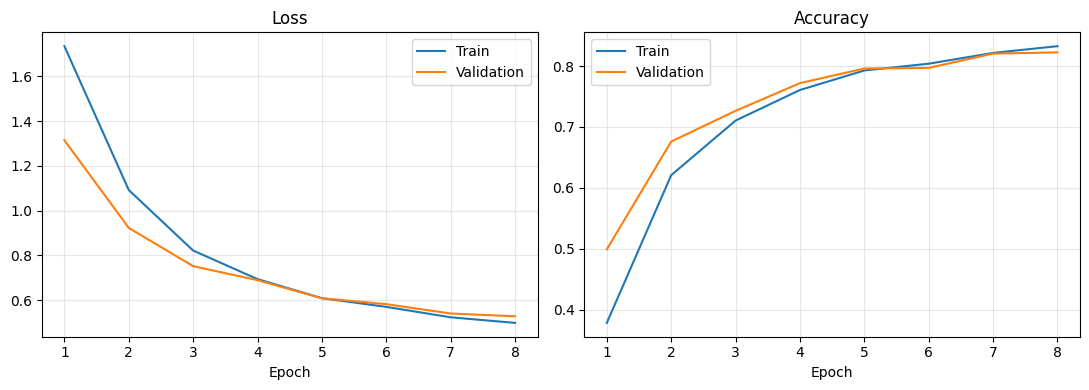

In [15]:
model = TinyViT()
result = fit_model(model)
plot_history(result)